In [38]:
import sys,os
sys.path.append('../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['p','o','h','^','*']
_linestyles = ['-','--','dotted']
plot_id = 0

[ 0 24 60]
[ 0 12 31]


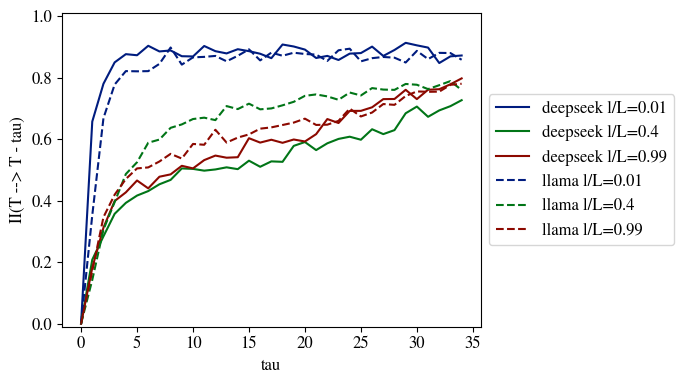

In [62]:
models = ['deepseek','llama']
depths = {"deepseek":61,
          "llama":32}
mask = 2
language_pairs = [('english','spanish'),
                  # ('german','hungarian'),
                  ]
n_files = 500
batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [35]

figsfolder = f'results/figs/'
os.makedirs(figsfolder,exist_ok=True)
fig,ax = plt.subplots(1,1,
                      figsize=(7,4),
                      # constrained_layout=True,
                      )
for n_tokens_id,n_tokens in enumerate(n_tokens_list):
  for model_id,model in enumerate(models):
    relative_depths = np.array([.01,0.4,.99])
    layer_ids = (relative_depths * depths[model]).astype(int)
    print(layer_ids)
    for r_id,r in enumerate(relative_depths):
      if model == 'deepseek':
        _model = 'V3'
      elif model =='llama':
        _model = 'L3'
      for language_pair_id, language_pair in enumerate(language_pairs):
        (languageA,languageB) = language_pair
        II_folder = makefolder(base=f'./results/santiago/',
                                  model=model,
                                  n_files=n_files,
                                  languageA=languageA,
                                  # languageB=languageB,
                                  mask=mask,
                                  )
        IIs = np.load(II_folder + f'n_tokens_{n_tokens}.npy')
        ax.plot(range(n_tokens),
                IIs[:,layer_ids[r_id],:].mean(axis=0),
                linestyle=_linestyles[model_id],
                label=f'{model} l/L={relative_depths[r_id]}',
                # marker=markers[model_id],
                color=colors[r_id%len(colors)],)
  ax.set_xlabel('tau')
  ax.set_ylabel('II(T --> T - tau)')
  ax.set_ylim(-0.01,1.01)
  box = ax.get_position()
  ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
  ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
  fig.savefig(f'{figsfolder}token-axis-II.pdf',bbox_inches='tight')

In [ ]:
models = ['deepseek']
mask = 2
language_pairs = [('english','spanish'),
                  # ('german','hungarian'),
                  ]
n_files = 500
batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [35]

layer_ids = [10,20,40,50,60]
fig,ax = plt.subplots(1,1,
                      figsize=(7,4),
                      # constrained_layout=True,
                      )
for n_tokens_id,n_tokens in enumerate(n_tokens_list):
  for layer_index,layer_id in enumerate(layer_ids):

    for model_id,model in enumerate(models):
      if model == 'deepseek':
        _model = 'DS'
      elif model =='llama':
        _model = 'L3'
      for language_pair_id, language_pair in enumerate(language_pairs):
        (languageA,languageB) = language_pair
        II_folder = makefolder(base=f'./results/santiago/',
                                  model=model,
                                  n_files=n_files,
                                  languageA=languageA,
                                  languageB=languageB,
                                  mask=mask,
                                  )
        IIs = np.load(II_folder + f'n_tokens_{n_tokens}.npy')
        ax.plot(range(n_tokens),
                IIs[0,layer_id,:]-IIs[1,layer_id,:],
                linestyle=_linestyles[0],
                label=f'l={layer_id}',
                marker='o',
                color=colors[layer_index],)
  ax.set_xlabel('tau')
  # ax.vlines()
  # ax.set_ylabel('II(T --> T - tau) - ')
  ax.legend()
